# 01 · Explore the data

Loads SPY from the local store, compares adjusted and unadjusted closes, and shows the
data-quality summary. Run `uv run qr init && uv run qr ingest` first.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from qr import storage, validate
from qr.config import db_path
from qr.load import get_bars, get_returns, list_symbols

# The notebook lives in notebooks/, the data directory one level up.
DATA_DIR = Path(os.environ.get("QR_DATA_DIR", Path.cwd().parent / "data"))
list_symbols(data_dir=DATA_DIR)

['AAPL',
 'BTC/USD',
 'CVX',
 'GLD',
 'GS',
 'HD',
 'IWM',
 'KO',
 'LOW',
 'MA',
 'MS',
 'MSFT',
 'PEP',
 'QQQ',
 'SPY',
 'TLT',
 'V',
 'XOM']

## SPY in the three adjustment modes

`get_bars` returns a `(date, symbol)` MultiIndex. Prices are stored unadjusted; split and
total-return adjustment are computed at load time.

In [2]:
spy = {
    mode: get_bars("SPY", adjustment=mode, data_dir=DATA_DIR).droplevel("symbol")
    for mode in ("none", "split", "total_return")
}
spy["total_return"].tail()

,open,high,low,close,volume
date,,,,,
2026-10-06,778.150024,781.619995,777.960022,779.090027,36054300.0
2026-10-07,775.770020,779.099976,773.609985,777.219971,30989200.0
2026-10-08,774.859985,777.090027,770.440002,773.929993,40431100.0
2026-10-09,776.239990,779.419983,775.140015,778.570007,22624500.0
2026-10-12,778.780029,779.400024,777.049988,778.099976,18639800.0


In [3]:
closes = pd.DataFrame({mode: frame["close"] for mode, frame in spy.items()})
closes.iloc[[0, len(closes) // 2, -1]]

,none,split,total_return
date,,,
2010-01-04,113.330002,113.330002,84.368997
2018-05-21,273.369995,273.369995,240.357002
2026-10-12,778.099976,778.099976,778.099976


## Adjusted vs. unadjusted close

SPY has never split, so the whole difference is dividends: the total-return series starts
lower because every dividend paid since then has been folded back into earlier prices.

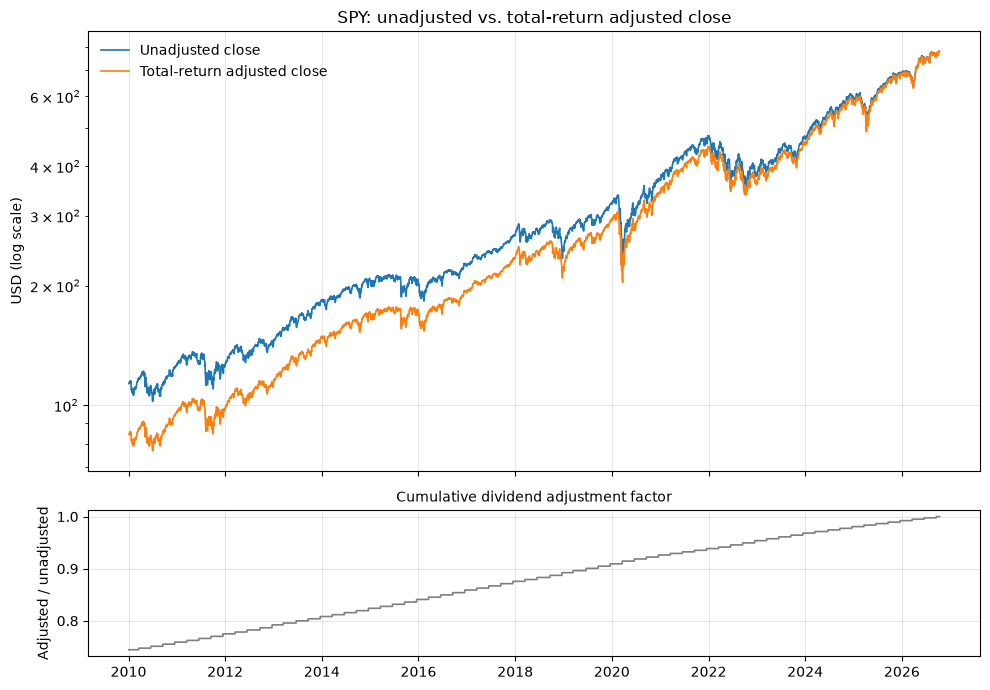

In [4]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, height_ratios=[3, 1])

top.plot(closes.index, closes["none"], label="Unadjusted close", linewidth=1.2)
top.plot(closes.index, closes["total_return"], label="Total-return adjusted close", linewidth=1.2)
top.set_yscale("log")
top.set_ylabel("USD (log scale)")
top.set_title("SPY: unadjusted vs. total-return adjusted close")
top.legend(frameon=False)
top.grid(alpha=0.3)

bottom.plot(closes.index, closes["total_return"] / closes["none"], color="tab:gray", linewidth=1.2)
bottom.set_ylabel("Adjusted / unadjusted")
bottom.set_title("Cumulative dividend adjustment factor", fontsize=10)
bottom.grid(alpha=0.3)

fig.tight_layout()
plt.show()

What dividends are worth over the whole period: price-only growth versus total return.

In [5]:
growth = closes.iloc[-1] / closes.iloc[0]
pd.DataFrame(
    {"growth multiple": growth.round(2)},
    index=["none", "total_return"],
).rename(index={"none": "price only", "total_return": "with dividends reinvested"})

,growth multiple
price only,6.87
with dividends reinvested,9.22


## Validation summary

Open findings in `quality_issues`, grouped by symbol and check, plus per-symbol coverage.
An empty table means every check passed.

In [6]:
with storage.connect(db_path(DATA_DIR), read_only=True) as con:
    issues = storage.read_quality_issues(con)
    coverage = storage.read_coverage(con)

print(f"{len(issues)} open findings")
validate.summarize(issues)

0 open findings


,symbol,check_name,severity,count,first_date,last_date


In [7]:
coverage

,symbol,source,asset_class,is_active,first_date,last_date,n_rows,errors,warnings
0,AAPL,yahoo,equity,True,2010-01-04,2026-10-12,4219,0,0
1,BTC/USD,crypto,crypto,False,NaT,NaT,0,0,0
2,CVX,yahoo,equity,True,2010-01-04,2026-10-12,4219,0,0
3,GLD,yahoo,etf,True,2010-01-04,2026-10-12,4219,0,0
4,GS,yahoo,equity,True,2010-01-04,2026-10-12,4219,0,0
5,HD,yahoo,equity,True,2010-01-04,2026-10-12,4219,0,0
6,IWM,yahoo,etf,True,2010-01-04,2026-10-12,4219,0,0
7,KO,yahoo,equity,True,2010-01-04,2026-10-12,4219,0,0
8,LOW,yahoo,equity,True,2010-01-04,2026-10-12,4219,0,0
9,MA,yahoo,equity,True,2010-01-04,2026-10-12,4219,0,0


## Daily returns

`get_returns` gives a wide (date × symbol) table of total returns (log by default).

In [8]:
returns = get_returns(["SPY", "TLT", "GLD"], kind="simple", data_dir=DATA_DIR)
returns.describe().loc[["count", "mean", "std", "min", "max"]]

symbol,SPY,TLT,GLD
count,4218.000000,4218.000000,4218.000000
mean,0.000585,0.000128,0.000352
std,0.010732,0.009380,0.010575
min,-0.109424,-0.066683,-0.102742
max,0.105019,0.075196,0.063587
